# Wider time-scale study: momentum and reversal

## tl;dr

Zero-cost pattern discovery is primary; 20 bps economics are a secondary check. The wider scan tests **156 configurations**, not just the two original winning configurations.

- Momentum 4h/24h: 2025 gross return 0.02%, gross Sharpe 0.11; 20 bps net return -60.29%, net Sharpe -4.00.
- Reversal 2h/4h: 2025 gross return 13.59%, gross Sharpe 0.77; 20 bps net return -99.63%, net Sharpe -31.91.

**Exploratory, not a fresh held-out test:** 2025 was already inspected in the original project. Selecting candidates from 2024 only avoids selecting on these plotted 2025 results, but cannot make this follow-up an untouched out-of-sample experiment.

## Context & Methods

- Both families use every lookback: **1, 2, 4, 8, 12, 24, 48, 72, 168, 336, 672, 1,440, 2,160 hours** (1 hour to 90 days).
- Rebalance spacings: **1, 4, 12, 24, 72, 168 hours** (hourly to weekly), UTC-anchored to Monday January 3, 2022. Cadence is decision spacing, not a minimum holding period.
- 13 lookbacks x 6 spacings x 2 families = 156 configurations. All share development beginning March 7, 2022, validation 2024, and exploratory evaluation 2025.
- The same rank/demean/unit-gross dollar-neutral construction, 365-day daily metrics, BTC alpha/beta HAC(7), theoretical shorts, and documented 2023 halt protocol apply.
- Longer horizons measure elapsed time, not number of surviving observations. Source missing prices are not filled.
- The primary selection criterion is highest **2024 gross Sharpe**, separately for each family; a separately reported net-selected pair uses 2024 net Sharpe at 20 bps.
- Zero execution cost is not achievable profit. Funding, borrow, margin, capacity, drift and guaranteed fills remain excluded.

All original reports, notebook, selections, source definitions and deliverable ZIP are preserved. This companion writes only inside the isolated follow-up directory.

## Data

### 1. Load the isolated evidence

Local source files are `metrics.csv`, `annual_metrics.csv`, `selection.json`, `candidate_returns.parquet`, `robustness.csv`, and `scan_manifest.json`. No download or parameter search is executed by this notebook.

In [1]:
from pathlib import Path
import json, hashlib, sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
from matplotlib.ticker import PercentFormatter
from matplotlib.colors import LinearSegmentedColormap, TwoSlopeNorm
from IPython.display import display

choices = [Path.cwd(), Path.cwd()/'outputs/followups/time_scale_scan']
SCAN = next(p for p in choices if (p/'scan_manifest.json').exists())
PROJECT = SCAN.parents[2]
sys.path.insert(0,str(PROJECT/'src'))
sys.path.insert(0,str(SCAN))
get_ipython().run_line_magic('matplotlib','inline')
HORIZONS = [1,2,4,8,12,24,48,72,168,336,672,1440,2160]
CADENCES = [1,4,12,24,72,168]
COLORS = {'momentum':'#245C85','reversal':'#B66C24'}
plt.rcParams.update({'font.size':10,'axes.spines.top':False,'axes.spines.right':False})
metrics = pd.read_csv(SCAN/'metrics.csv')
annual = pd.read_csv(SCAN/'annual_metrics.csv')
selection = json.loads((SCAN/'selection.json').read_text())
manifest = json.loads((SCAN/'scan_manifest.json').read_text())
returns = pd.read_parquet(SCAN/'candidate_returns.parquet')
returns['bar_end'] = pd.to_datetime(returns['bar_end'],utc=True)
robustness = pd.read_csv(SCAN/'robustness.csv')
intervals = pd.read_csv(SCAN/'nominal_bootstrap_intervals.csv')
counts = pd.read_csv(SCAN/'profitability_counts.csv')
break_even = pd.DataFrame(json.loads((SCAN/'break_even.json').read_text())['rows'])
selection_digest = hashlib.sha256((SCAN/'selection.json').read_bytes()).hexdigest()
gross_selected = selection['gross_selected']
net_selected = selection['net_selected']
print('Python:',sys.executable)
print('Follow-up:',SCAN)
print('Status:',manifest['research_status'])


Python: /Users/cosdis/.venvs/myenv/bin/python
Follow-up: /Users/cosdis/Desktop/job/quant_projects/crypto_stat_arb/outputs/followups/time_scale_scan
Status: Post-hoc exploratory extension; 2025 previously inspected.


In [2]:
def label(row):
    return f"{row['family'].title()} {int(row['lookback_h'])}h/{int(row['rebalance_h'])}h"


### 2. Check grid completeness and the saved selection evidence

These are full-grid checks, not a selective preview. A decrease in return when trading costs are added is an accounting requirement, not evidence of statistical significance.

In [3]:
assert manifest['original_artifacts_unchanged'] is True
for relative,digest in manifest['original_artifact_sha256'].items():
    assert hashlib.sha256((PROJECT/relative).read_bytes()).hexdigest() == digest,relative
for relative,digest in manifest['output_sha256'].items():
    assert hashlib.sha256((SCAN/relative).read_bytes()).hexdigest() == digest,relative
assert hashlib.sha256((SCAN/selection['evidence_file']).read_bytes()).hexdigest() == selection['selection_evidence_sha256']
assert pd.Timestamp(selection['frozen_at_utc']) < pd.Timestamp(manifest['exploratory_test_started_at_utc'])
assert len(metrics) == 936
assert len(annual) == 1248
keys = ['experiment_id','split','cost_bps']
assert not metrics.duplicated(keys).any()
assert set(metrics['family']) == {'momentum','reversal'}
assert set(metrics['lookback_h']) == set(HORIZONS)
assert set(metrics['rebalance_h']) == set(CADENCES)
assert set(metrics['cost_bps']) == {0,20}
assert set(metrics['split']) == {'development','validation','test'}
for family, group in metrics.groupby('family'):
    assert len(group[['lookback_h','rebalance_h']].drop_duplicates()) == 78
paired = metrics.pivot(index=['experiment_id','split'],columns='cost_bps',values='total_return')
assert (paired[20] <= paired[0] + 1e-12).all()
for criterion, picks, cost in [('gross',gross_selected,0),('net',net_selected,20)]:
    assert len(picks) == 2
    for s in picks:
        validation = metrics.loc[metrics['family'].eq(s['family']) & metrics['split'].eq('validation') & metrics['cost_bps'].eq(cost)]
        winner = validation.sort_values(['sharpe','mean_hourly_turnover','experiment_id'],ascending=[False,True,True]).iloc[0]
        assert winner['experiment_id'] == s['experiment_id']
print('Passed: 936 split/cost rows; 1,248 yearly rows; 78 configurations per family; frozen gross/net choices.')
display(pd.DataFrame(gross_selected)[['experiment_id','family','lookback_h','rebalance_h']])


Passed: 936 split/cost rows; 1,248 yearly rows; 78 configurations per family; frozen gross/net choices.


,experiment_id,family,lookback_h,rebalance_h
0,momentum_h0004_r024,momentum,4,24
1,reversal_h0002_r004,reversal,2,4


### Reconcile the four frozen candidates from cached prices

Rebuild extended-schedule weights, derive gross returns and L1 turnover from positions, recompute 2025 metrics at 0 and 20 bps, and compare every saved frame column. This is not a parameter sweep or a new selection.

In [4]:
from crypto_stat_arb.data import load_panel
from crypto_stat_arb.backtest import simulate
from crypto_stat_arb.metrics import summarize
from extended_backtest import generate_scaled_targets
prices,_,audit=load_panel(PROJECT)
benchmark=prices['BTCUSDT'].pct_change(fill_method=None)
unique={s['experiment_id']:s for s in gross_selected+net_selected}
reconciliation=[]
for experiment_id,s in unique.items():
    targets=generate_scaled_targets(prices,s['family'],s['lookback_h'],s['rebalance_h'])
    for cost in [0,20]:
        result=simulate(prices,targets,'2025-01-01','2026-01-01',cost,1)
        f=result.frame
        asset_return=prices.pct_change(fill_method=None).reindex(f.index)
        manual_gross=(result.held_weights*asset_return).sum(axis=1)
        changes=result.held_weights.diff();changes.iloc[0]=result.held_weights.iloc[0]
        manual_turnover=changes.abs().sum(axis=1)
        manual_turnover.iloc[-1]+=result.held_weights.iloc[-1].abs().sum()
        np.testing.assert_allclose(f['net_return'],manual_gross-manual_turnover*cost*1e-4,atol=1e-13)
        saved=returns.loc[returns['experiment_id'].eq(experiment_id)&returns['split'].eq('test')&returns['cost_bps'].eq(cost)].set_index('bar_end').sort_index()
        assert f.index.equals(saved.index)
        for column in ['gross_return','net_return','turnover','cost','equity','drawdown']:
            np.testing.assert_allclose(f[column],saved[column],rtol=1e-10,atol=1e-13)
        computed=summarize(result,benchmark)
        row=metrics.loc[metrics['experiment_id'].eq(experiment_id)&metrics['split'].eq('test')&metrics['cost_bps'].eq(cost)].iloc[0]
        for column in ['total_return','cagr','annual_return','annual_volatility','sharpe','max_drawdown','alpha_annual','beta']:
            np.testing.assert_allclose(computed[column],row[column],rtol=1e-10,atol=1e-12)
        reconciliation.append({'candidate':label(s),'cost bps':cost,'hours verified':len(f),'reconciled':True})
assert hashlib.sha256((SCAN/'selection.json').read_bytes()).hexdigest()==selection_digest
display(pd.DataFrame(reconciliation))


,candidate,cost bps,hours verified,reconciled
0,Momentum 4h/24h,0,8760,True
1,Momentum 4h/24h,20,8760,True
2,Reversal 2h/4h,0,8760,True
3,Reversal 2h/4h,20,8760,True
4,Momentum 2160h/168h,0,8760,True
5,Momentum 2160h/168h,20,8760,True
6,Reversal 672h/168h,0,8760,True
7,Reversal 672h/168h,20,8760,True


## Results

### 3. Map the entire 2025 zero-cost surface

Every one of the 78 combinations appears for each family. Both heatmaps use the same symmetric color scale and exact cell annotations. The chart is **post-hoc exploratory**: a 2025 high-Sharpe cell is not a newly selected strategy or an unbiased performance estimate.

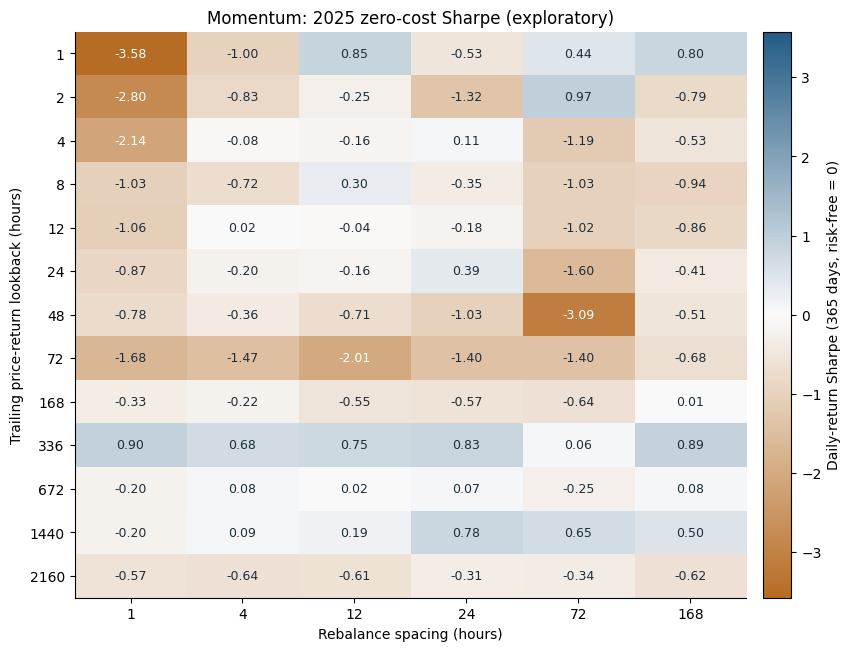

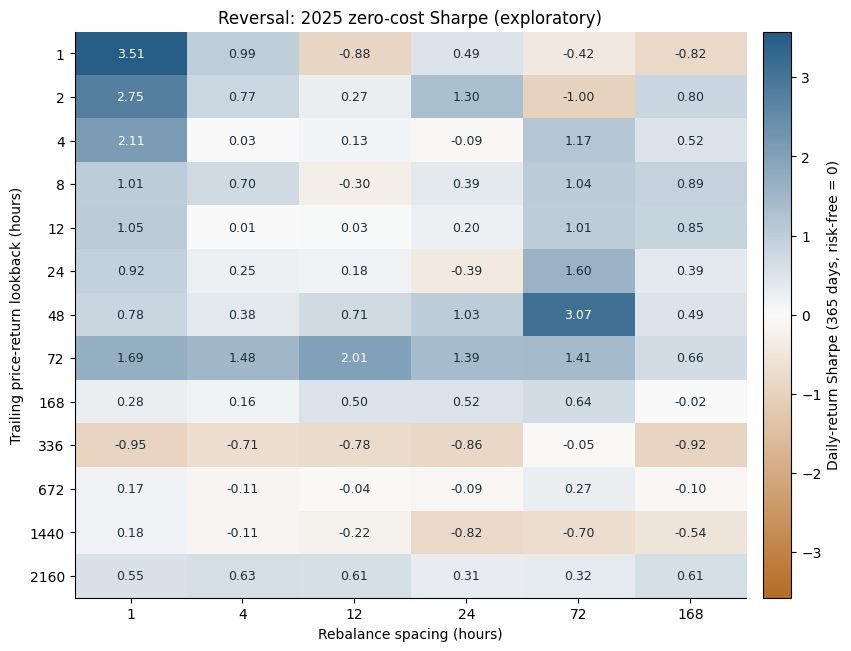

In [5]:
def plot_heatmaps(metrics):
    data = metrics.loc[metrics['split'].eq('test') & metrics['cost_bps'].eq(0)]
    bound = float(data['sharpe'].abs().max())
    cmap = LinearSegmentedColormap.from_list('signal_strength', ['#B66C24', '#FAFAFA', '#245C85'])
    norm = TwoSlopeNorm(vmin=-bound, vcenter=0, vmax=bound)
    figures = {}
    for family in ['momentum', 'reversal']:
        rows = data.loc[data['family'].eq(family)]
        matrix = rows.pivot(index='lookback_h', columns='rebalance_h', values='sharpe').reindex(index=HORIZONS, columns=CADENCES)
        fig, ax = plt.subplots(figsize=(8.4, 6.4), layout='constrained')
        image = ax.imshow(matrix.to_numpy(), cmap=cmap, norm=norm, aspect='auto')
        ax.set_xticks(range(len(CADENCES)), [str(h) for h in CADENCES])
        ax.set_yticks(range(len(HORIZONS)), [str(h) for h in HORIZONS])
        ax.set(xlabel='Rebalance spacing (hours)', ylabel='Trailing price-return lookback (hours)',
               title=f'{family.title()}: 2025 zero-cost Sharpe (exploratory)')
        for i, horizon in enumerate(HORIZONS):
            for j, cadence in enumerate(CADENCES):
                value = matrix.loc[horizon, cadence]
                color = '#FFFFFF' if abs(value) > .55 * bound else '#1D2E3A'
                ax.text(j, i, f'{value:.2f}', ha='center', va='center', color=color, fontsize=9)
        bar = fig.colorbar(image, ax=ax, pad=.025)
        bar.set_label('Daily-return Sharpe (365 days, risk-free = 0)')
        figures[family] = fig
    return figures

heatmaps = plot_heatmaps(metrics)
for family, figure in heatmaps.items():
    figure.savefig(SCAN/f'figures/{family}_zero_cost_sharpe.png',dpi=180,bbox_inches='tight')
    display(figure)
    plt.close(figure)

### 4. Compare validation with the already-seen evaluation year

The dashed diagonal indicates unchanged gross Sharpe; zero lines distinguish sign persistence. Scatter points are configurations, not independent statistical samples.

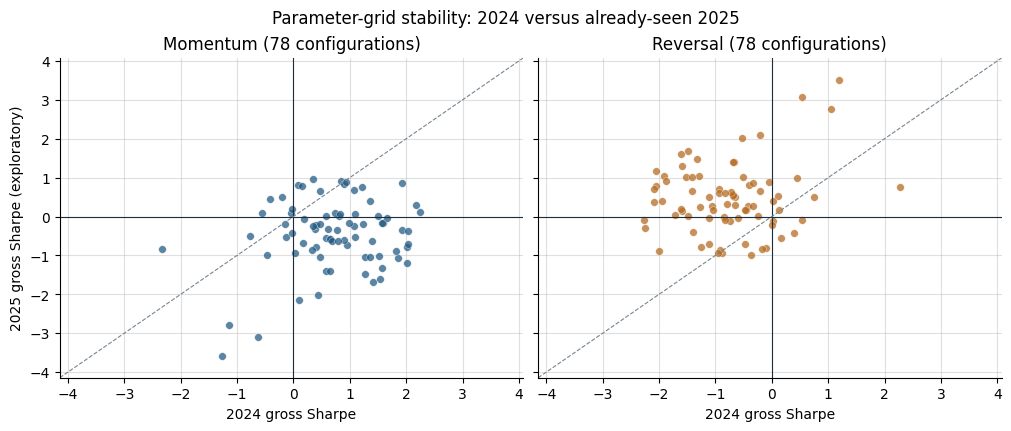

,positive_2024,positive_2025,positive_both
family,,,
momentum,64,24,19
reversal,14,55,9


In [6]:
def plot_stability(metrics):
    zero = metrics.loc[metrics['cost_bps'].eq(0)]
    pair = zero.pivot(index=['experiment_id', 'family'], columns='split', values='sharpe').reset_index()
    minimum = float(min(pair['validation'].min(), pair['test'].min()))
    maximum = float(max(pair['validation'].max(), pair['test'].max()))
    margin = max((maximum - minimum) * .08, .1)
    fig, axes = plt.subplots(1, 2, figsize=(10, 4.2), sharex=True, sharey=True, layout='constrained')
    for ax, family in zip(axes, ['momentum', 'reversal']):
        g = pair.loc[pair['family'].eq(family)]
        ax.scatter(g['validation'], g['test'], s=30, alpha=.75, color=COLORS[family], edgecolors='white', linewidth=.3)
        ax.axhline(0, color='#1D2E3A', lw=.8); ax.axvline(0, color='#1D2E3A', lw=.8)
        ax.plot([minimum-margin, maximum+margin], [minimum-margin, maximum+margin], ls='--', color='#77858F', lw=.8)
        ax.set(title=f'{family.title()} (78 configurations)', xlabel='2024 gross Sharpe',
               xlim=(minimum-margin,maximum+margin), ylim=(minimum-margin,maximum+margin))
        ax.grid(alpha=.4); ax.set_axisbelow(True)
    axes[0].set_ylabel('2025 gross Sharpe (exploratory)')
    fig.suptitle('Parameter-grid stability: 2024 versus already-seen 2025', fontsize=12)
    return fig

stability_figure = plot_stability(metrics)
stability_figure.savefig(SCAN/'figures/validation_test_stability.png',dpi=180,bbox_inches='tight')
display(stability_figure);plt.close(stability_figure)
zero = metrics.loc[metrics['cost_bps'].eq(0)]
persistence = zero.pivot(index=['experiment_id','family'],columns='split',values='sharpe').reset_index()
display(persistence.groupby('family').apply(lambda g:pd.Series({'positive_2024':int((g['validation']>0).sum()),'positive_2025':int((g['test']>0).sum()),'positive_both':int(((g['validation']>0)&(g['test']>0)).sum())}),include_groups=False))

### 5. Compare gross discovery with trading-cost economics

Only the **2024 gross-selected** candidates are plotted. The separately net-selected candidates appear in a table below, without replacing the primary gross research question. Both families use the same equity axis, start capital, calendar year and cost convention.

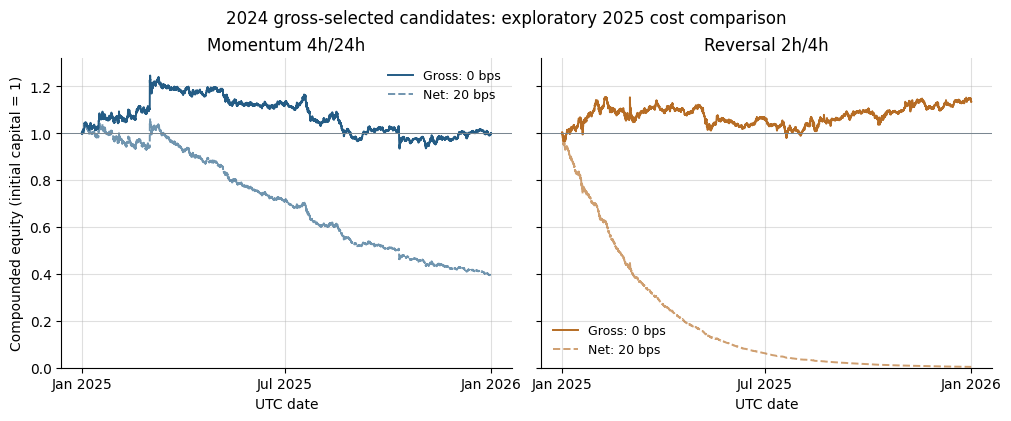

,selection,candidate,cost bps,2025 return,2025 Sharpe,max drawdown
0,2024 gross selected,Momentum 4h/24h,0,0.02%,0.111,25.01%
1,2024 gross selected,Momentum 4h/24h,20,-60.29%,-4.001,62.92%
2,2024 gross selected,Reversal 2h/4h,0,13.59%,0.772,15.07%
3,2024 gross selected,Reversal 2h/4h,20,-99.63%,-31.908,99.63%
4,2024 net selected,Momentum 2160h/168h,0,-12.44%,-0.617,27.81%
5,2024 net selected,Momentum 2160h/168h,20,-16.11%,-0.848,30.31%
6,2024 net selected,Reversal 672h/168h,0,-3.56%,-0.099,14.02%
7,2024 net selected,Reversal 672h/168h,20,-10.02%,-0.468,16.55%


In [7]:
def plot_candidate_equity(candidate_returns, gross_selected):
    figures = {}
    maximum = 1.0
    for s in gross_selected:
        g = candidate_returns.loc[candidate_returns['experiment_id'].eq(s['experiment_id']) & candidate_returns['split'].eq('test')]
        for _, q in g.groupby('cost_bps'):
            maximum = max(maximum, float((1 + q.sort_values('bar_end')['net_return']).cumprod().max()))
    fig, axes = plt.subplots(1, 2, figsize=(10, 4.1), sharey=True, layout='constrained')
    for ax, s in zip(axes, gross_selected):
        g = candidate_returns.loc[candidate_returns['experiment_id'].eq(s['experiment_id']) & candidate_returns['split'].eq('test')]
        for cost, q in g.groupby('cost_bps'):
            q = q.sort_values('bar_end')
            dates = pd.DatetimeIndex(q['bar_end']).insert(0, q['bar_end'].iloc[0] - pd.Timedelta(hours=1))
            equity = np.r_[1.0, (1 + q['net_return']).cumprod().to_numpy()]
            ax.plot(dates, equity, color=COLORS[s['family']], ls='-' if cost == 0 else '--',
                    lw=1.4, alpha=1 if cost == 0 else .65, label='Gross: 0 bps' if cost == 0 else 'Net: 20 bps')
        ax.axhline(1, color='#77858F', lw=.7)
        ax.set(title=label(s), xlabel='UTC date', ylim=(0,maximum*1.06))
        ax.xaxis.set_major_locator(mdates.MonthLocator(bymonth=[1,7]))
        ax.xaxis.set_major_formatter(mdates.DateFormatter('%b %Y'))
        ax.legend(frameon=False, fontsize=9); ax.grid(alpha=.4); ax.set_axisbelow(True)
    axes[0].set_ylabel('Compounded equity (initial capital = 1)')
    fig.suptitle('2024 gross-selected candidates: exploratory 2025 cost comparison', fontsize=12)
    return fig

equity_figure = plot_candidate_equity(returns,gross_selected)
equity_figure.savefig(SCAN/'figures/gross_selected_cost_comparison.png',dpi=180,bbox_inches='tight')
display(equity_figure);plt.close(equity_figure)
rows=[]
for criterion,picks in [('2024 gross selected',gross_selected),('2024 net selected',net_selected)]:
    for s in picks:
        for cost in [0,20]:
            row=metrics.loc[metrics['experiment_id'].eq(s['experiment_id']) & metrics['split'].eq('test') & metrics['cost_bps'].eq(cost)].iloc[0]
            rows.append({'selection':criterion,'candidate':label(s),'cost bps':cost,'2025 return':f"{row['total_return']:.2%}",'2025 Sharpe':round(row['sharpe'],3),'max drawdown':f"{row['max_drawdown']:.2%}"})
display(pd.DataFrame(rows))

### 6. Inspect year-by-year stability and phase/delay stresses

2022 is a partial development year (March 7-December 31); it is labeled accordingly and is not directly equal in duration to the three subsequent full years. Yearly accounting resets cash and liquidates at each boundary. Phase/delay scenarios reuse the frozen candidates.

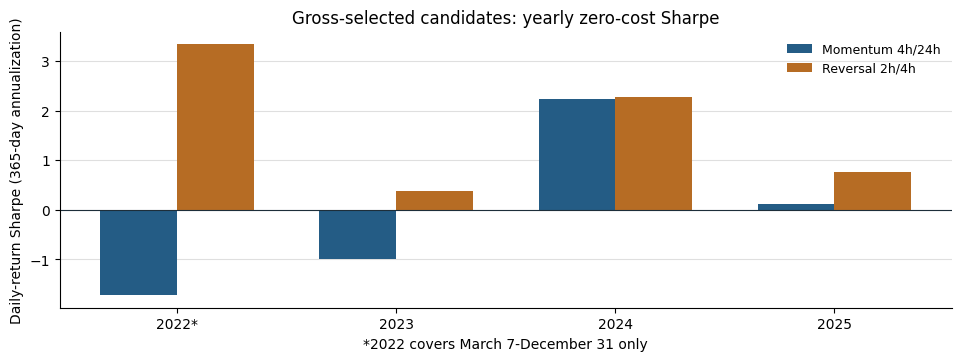

,candidate,scenario,phase_hours,execution_lag,cost_bps,2025 return,sharpe
2,Momentum 4h/24h,primary,0,1,0,0.02%,0.111
3,Momentum 4h/24h,primary,0,1,20,-60.29%,-4.001
6,Momentum 4h/24h,extra_hour_delay,0,2,0,-4.42%,-0.087
7,Momentum 4h/24h,extra_hour_delay,0,2,20,-62.13%,-4.174
10,Momentum 4h/24h,half_cadence_phase_shift,12,1,0,8.68%,0.532
11,Momentum 4h/24h,half_cadence_phase_shift,12,1,20,-57.07%,-4.272
14,Reversal 2h/4h,primary,0,1,0,13.59%,0.772
15,Reversal 2h/4h,primary,0,1,20,-99.63%,-31.908
18,Reversal 2h/4h,extra_hour_delay,0,2,0,3.47%,0.264
19,Reversal 2h/4h,extra_hour_delay,0,2,20,-99.67%,-27.576


In [8]:
def plot_annual(annual_metrics, gross_selected):
    ids = [s['experiment_id'] for s in gross_selected]
    a = annual_metrics.loc[annual_metrics['experiment_id'].isin(ids) & annual_metrics['cost_bps'].eq(0)]
    years = sorted(a['year'].unique())
    fig, ax = plt.subplots(figsize=(9.5, 3.5), layout='constrained')
    width = .35
    xs = np.arange(len(years))
    for j, s in enumerate(gross_selected):
        g = a.loc[a['experiment_id'].eq(s['experiment_id'])].set_index('year').reindex(years)
        ax.bar(xs + (j-.5)*width, g['sharpe'], width, label=label(s), color=COLORS[s['family']])
    ax.axhline(0,color='#1D2E3A',lw=.8)
    ax.set_xticks(xs,[str(y) + ('*' if y == 2022 else '') for y in years])
    ax.set(title='Gross-selected candidates: yearly zero-cost Sharpe',
           ylabel='Daily-return Sharpe (365-day annualization)', xlabel='*2022 covers March 7-December 31 only')
    ax.grid(axis='y',alpha=.4);ax.set_axisbelow(True);ax.legend(frameon=False,fontsize=9)
    return fig

annual_figure=plot_annual(annual,gross_selected)
annual_figure.savefig(SCAN/'figures/selected_yearly_sharpe.png',dpi=180,bbox_inches='tight')
display(annual_figure);plt.close(annual_figure)
stress=robustness.loc[robustness['split'].eq('test')].copy()
stress['candidate']=[label(r) for _,r in stress.iterrows()]
stress['2025 return']=stress['total_return'].map(lambda x:f'{x:.2%}')
display(stress[['candidate','scenario','phase_hours','execution_lag','cost_bps','2025 return','sharpe']].round(3))


### 7. Count broad yearly persistence without changing the selections

The table below is **retrospectively selected after examining all four years**: it describes the full scan, not additional frozen winners. Each included configuration had positive gross compounded return in 2022 (partial), 2023, 2024 and 2025. Requiring positivity in all observed years does not correct survivor, multiple-testing or selection biases.

In [9]:
annual_pair=annual.pivot(index=['experiment_id','family','lookback_h','rebalance_h','cost_bps'],columns='year',values='total_return').reset_index()
years=[2022,2023,2024,2025]
all_positive=annual_pair[years].gt(0).all(axis=1)
gross_persistent=annual_pair.loc[all_positive & annual_pair['cost_bps'].eq(0)].copy()
net_persistent=annual_pair.loc[all_positive & annual_pair['cost_bps'].eq(20)].copy()
print('Positive compounded returns in all four observed years:',len(gross_persistent),'at 0 bps;',len(net_persistent),'at 20 bps.')
view=gross_persistent[['family','lookback_h','rebalance_h']].copy()
for year in years:
    view[str(year)+('*' if year==2022 else '')]=gross_persistent[year].map(lambda x:f'{x:.2%}')
display(view.rename(columns={'lookback_h':'lookback hours','rebalance_h':'rebalance hours'}).reset_index(drop=True))
display(counts.loc[counts['split'].eq('test')][['family','cost_bps','n_configurations','positive_total_return','positive_sharpe']])


Positive compounded returns in all four observed years: 11 at 0 bps; 0 at 20 bps.


year,family,lookback hours,rebalance hours,2022*,2023,2024,2025
0,momentum,2,72,40.39%,40.56%,5.32%,17.43%
1,momentum,24,24,4.29%,1.90%,36.58%,6.37%
2,momentum,336,1,29.21%,16.12%,18.66%,15.99%
3,momentum,336,4,36.66%,22.78%,25.43%,11.40%
4,momentum,336,12,47.94%,19.76%,29.75%,12.93%
5,momentum,336,24,37.12%,16.07%,20.42%,14.39%
6,reversal,1,1,112.97%,54.39%,26.47%,103.40%
7,reversal,1,4,66.03%,16.73%,8.01%,19.87%
8,reversal,2,1,162.27%,88.75%,22.50%,69.66%
9,reversal,2,4,88.50%,6.14%,61.86%,13.59%


,family,cost_bps,n_configurations,positive_total_return,positive_sharpe
4,momentum,0,78,17,24
5,momentum,20,78,3,5
6,reversal,0,78,52,55
7,reversal,20,78,4,5


### 8. Nominal uncertainty and break-even execution costs

Circular-block bootstrap intervals below use 5,000 resamples with 7- or 28-day blocks and saved seeds. They estimate the **annualized arithmetic mean of daily returns**, not CAGR or Sharpe. Intervals are nominal and **not adjusted for selection or 156 related comparisons**. The 0 bps selected-candidate intervals are plotted; the table includes 20 bps. Break-even cost is the one-way cost where 2025 compounded total return is zero, not an estimated achievable fill cost.

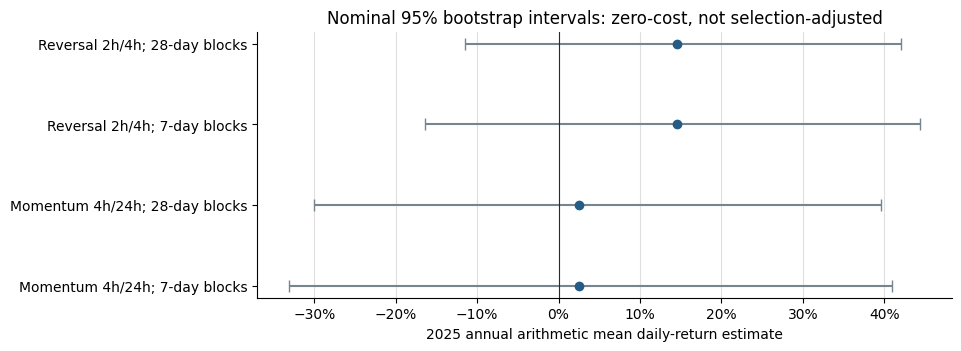

,family,cost_bps,block_days,arithmetic_annual_mean,ci95_low,ci95_high
0,momentum,0,7,2.50%,-33.12%,40.94%
1,momentum,0,28,2.50%,-30.03%,39.56%
2,momentum,20,7,-89.77%,-126.08%,-52.05%
3,momentum,20,28,-89.77%,-123.04%,-54.65%
4,reversal,0,7,14.51%,-16.34%,44.39%
5,reversal,0,28,14.51%,-11.50%,42.00%
6,reversal,20,7,-554.57%,-582.43%,-527.87%
7,reversal,20,28,-554.57%,-578.24%,-528.82%


,family,lookback_h,rebalance_h,break_even_cost_bps,criterion
0,momentum,4,24,0.0052,zero compounded total return
1,reversal,2,4,0.4454,zero compounded total return


In [10]:
g=intervals.loc[intervals['cost_bps'].eq(0)].copy().sort_values(['family','block_days'])
fig,ax=plt.subplots(figsize=(9.5,3.4),layout='constrained')
y=np.arange(len(g))
means=g['arithmetic_annual_mean'].to_numpy()
errors=np.vstack([means-g['ci95_low'].to_numpy(),g['ci95_high'].to_numpy()-means])
ax.errorbar(means,y,xerr=errors,fmt='o',color='#245C85',ecolor='#77858F',capsize=4)
ax.set_yticks(y,[label(r)+f"; {int(r['block_days'])}-day blocks" for _,r in g.iterrows()])
ax.axvline(0,color='#1D2E3A',linewidth=.8)
ax.xaxis.set_major_formatter(PercentFormatter(1))
ax.set(title='Nominal 95% bootstrap intervals: zero-cost, not selection-adjusted',xlabel='2025 annual arithmetic mean daily-return estimate')
ax.grid(axis='x',alpha=.4);ax.set_axisbelow(True)
fig.savefig(SCAN/'figures/nominal_mean_return_intervals.png',dpi=180,bbox_inches='tight')
display(fig);plt.close(fig)
view=intervals[['family','cost_bps','block_days','arithmetic_annual_mean','ci95_low','ci95_high']].copy()
for c in ['arithmetic_annual_mean','ci95_low','ci95_high']:view[c]=view[c].map(lambda x:f'{x:.2%}')
display(view)
display(break_even[['family','lookback_h','rebalance_h','break_even_cost_bps','criterion']].round({'break_even_cost_bps':4}))


## Takeaways

A wider grid can locate different gross patterns but increases multiple-comparison risk. Positive zero-cost results are not executable profit, and positive 2025 results in this already-seen period are hypotheses for a future truly unexamined period. Neither family is presumed successful. Theoretical shorts, funding/borrow omissions, the survivor universe, exchange-specific prices, USDT denomination and close-based execution remain material limits.

### Sources and attribution

- [Binance public market-data documentation](https://github.com/binance/binance-public-data); cached checksum-audited hourly spot archives inherited from the original project.
- [Binance dataset terms](https://github.com/binance/binance-public-data/blob/master/TERMS_AND_CONDITIONS.md): dataset-derived notebook analysis, charts and results are shared under CC BY-NC-SA 4.0 for non-commercial research, with Binance Vision attribution. No endorsement is implied.
- The original class assignment defines the unconstrained framing and 20 bps cost sensitivity; this follow-up makes **zero cost primary** at the user's request.